In [1]:
#import pytorch and device agnostic code

import torch
from torch import nn

#torch version must be > 1.10.1
torch.__version__

'2.11.0+cu130'

In [2]:
#setup device agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
import zipfile
import requests
from pathlib import Path

#setup path to data folder
Data_path = Path("Data/")
Image_path = Data_path / "pizza_steak_sushi"

#If image folder doesnt exits , download it and prepare it...
if Image_path.is_dir():
  print(f"{Image_path} directory exists")
else:
  print(f"Did not found {Image_path} directory, creating one..")
  Image_path.mkdir(parents=True, exist_ok=True)

  #download pizza , steak and sushi data
  with open(Data_path/ "pizza_steak_sushi.zip","wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
    print(f"downloading the pizza , steak and sushi data")
    f.write(request.content)

  #unzip pizza , steak and sushi data
  with zipfile.ZipFile(Data_path /"pizza_steak_sushi.zip", "r") as zip_ref:
    print("unzipping pizza , steak and sushi data")
    zip_ref.extractall(Image_path)

Did not found Data/pizza_steak_sushi directory, creating one..
downloading the pizza , steak and sushi data
unzipping pizza , steak and sushi data


Become one with the data (data preparation)

We can inspect what's in our data directory by writing a small helper function to walk through each of the subdirectories and count the files present.

To do so, we'll use Python's in-built os.walk().

In [4]:
import os

def walk_through_dir(dir_path):
  """
  Walks through dir_path returning its contents.
  Args:
    dir_path (str or pathlib.Path): target directory

  Returns:
    A print out of:
      number of subdiretories in dir_path
      number of images (files) in each subdirectory
      name of each subdirectory
  """
  for dirpath , dirname , filenames in os.walk(dir_path):
    print(f"There are {len(dirname)} directories and {len(filenames)} images in {dirpath}")


In [5]:
walk_through_dir(Image_path)

There are 2 directories and 0 images in Data/pizza_steak_sushi
There are 3 directories and 0 images in Data/pizza_steak_sushi/test
There are 0 directories and 25 images in Data/pizza_steak_sushi/test/pizza
There are 0 directories and 31 images in Data/pizza_steak_sushi/test/sushi
There are 0 directories and 19 images in Data/pizza_steak_sushi/test/steak
There are 3 directories and 0 images in Data/pizza_steak_sushi/train
There are 0 directories and 78 images in Data/pizza_steak_sushi/train/pizza
There are 0 directories and 72 images in Data/pizza_steak_sushi/train/sushi
There are 0 directories and 75 images in Data/pizza_steak_sushi/train/steak


In [6]:
#setup train and test path

train_dir = Image_path / "train"
test_dir = Image_path / "test"

train_dir , test_dir

(PosixPath('Data/pizza_steak_sushi/train'),
 PosixPath('Data/pizza_steak_sushi/test'))

Random image path:Data/pizza_steak_sushi/test/steak/690177.jpg
Image class:steak
Image height:512
Image width :382


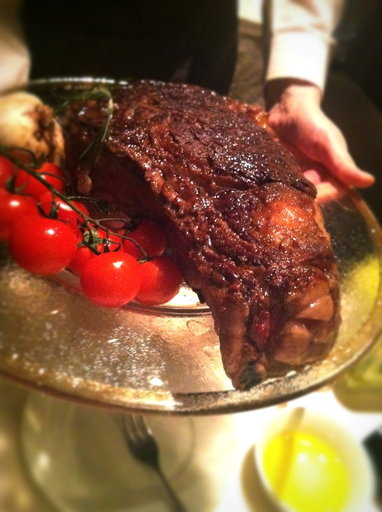

In [7]:
import random
from PIL import Image

#set seed
random.seed(42) #try changing this and see what happens

#1. get all image paths ( means any path combination "*/*/*.jpg")
image_path_lists = list(Image_path.glob("*/*/*.jpg"))

#2. get random image path
random_image_path = random.choice(image_path_lists)

#3. get the image class form the path name (the image class is the name if the directory where the image is)
image_class = random_image_path.parent.stem

#4. open image
image = Image.open(random_image_path)

#print meta data
print(f"Random image path:{random_image_path}")
print(f"Image class:{image_class}")
print(f"Image height:{image.height}")
print(f"Image width :{image.width}")
image



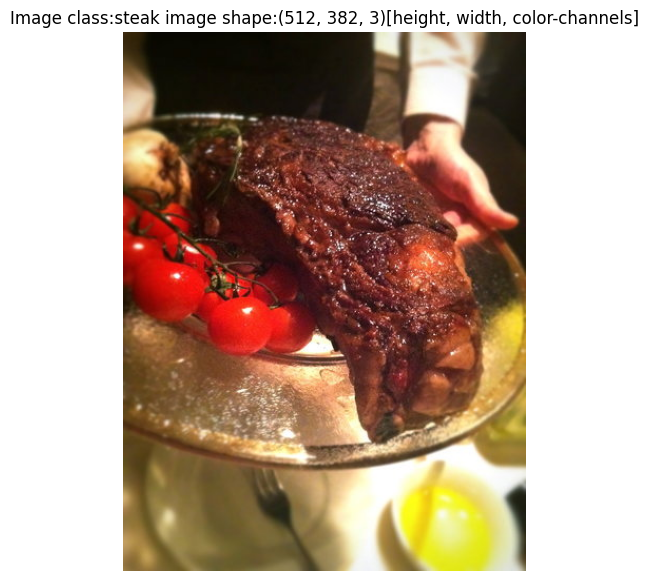

In [8]:
#we can do the same as did above in matplotlib except we have to change the image in numpy arrays

import matplotlib.pyplot as plt
import numpy as np

#turn the image into an array
image_array = np.asarray(image)

#plot the image with matplotlib

plt.figure(figsize=(10,7))
plt.imshow(image_array)
plt.title(f"Image class:{image_class} image shape:{image_array.shape}[height, width, color-channels]")
plt.axis(False);


In [9]:
import torch
from  torch.utils.data import DataLoader
from torchvision import datasets , transforms

In [10]:
#write transform for image
Data_transform = transforms.Compose([
    #resize the image to 64*64
    transforms.Resize(size=(64,64)),
    # randomly horizontallt flip the images
    transforms.RandomHorizontalFlip(p=0.5),  #p=porbability of flip , 0.5= 50% of chance
    #transform the PIL format images to pytorch tenors
    transforms.ToTensor()]  #also converts all pixel values from 0.0 to 1.0

)

Now we've got a composition of transforms, let's write a function to try them out on various images.

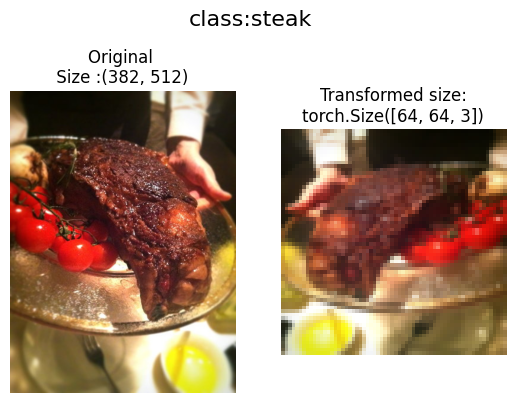

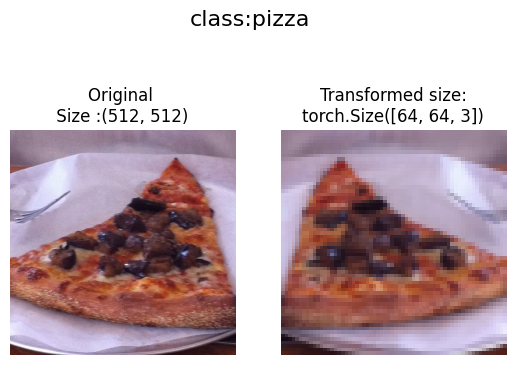

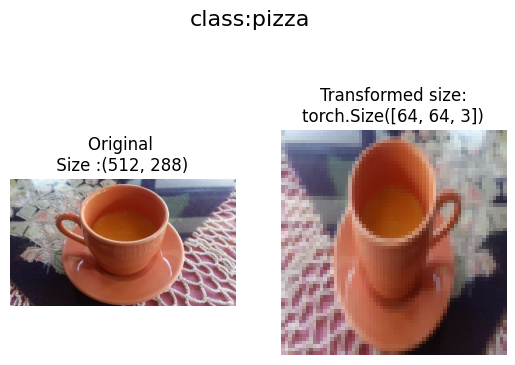

In [11]:
def plot_transformed_images(image_paths, transform , n=3, seed=42):
  """ Plots a series of random images form image_paths,

  will open n numbers of image paths  tranforms them with transforms
  and plot them side by side

  args:
    image_paths(list): list of target image paths
    tranforms(Pytorch transforms): Transforms to apply to images
    n(int, optional): Number of images to plot. defaults to 3
    seed(int, ooptional ): random seed for random generator . defaults to 42

    """

  random.seed(seed)
  random_image_paths = random.sample(image_paths, k=n)
  for image_path in random_image_paths:
    with Image.open(image_path) as f:
      fig , ax = plt.subplots(1,2)
      ax[0].imshow(f)
      ax[0].set_title(f"Original \n Size :{f.size} ")
      ax[0].axis("off")

      #transform and plot image
      ##Note : permute() will change the shape of the image to suite the matplotlib
      #Pytorch default is [c, h,w] but matplotlib uses [h, w, c]
      transformed_image = transform(f).permute(1,2,0)
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed size:\n{transformed_image.shape}")
      ax[1].axis("off")

      fig.suptitle(f"class:{image_path.parent.stem}", fontsize=16)


plot_transformed_images(image_path_lists,
                        transform=Data_transform,
                        n=3)



In [12]:
#use image folder to create dataset

from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir, #target folder of images
                                  transform = Data_transform, #transforms to perform on data(images)
                                  target_transform = None) #transforms to perform on labels if necessary


test_data = datasets.ImageFolder(root=test_dir,
                                 transform = Data_transform)

print(f"Train data:\n{train_data} \n Test data:\n{test_data}")



Train data:
Dataset ImageFolder
    Number of datapoints: 225
    Root location: Data/pizza_steak_sushi/train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           ) 
 Test data:
Dataset ImageFolder
    Number of datapoints: 75
    Root location: Data/pizza_steak_sushi/test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )


In [13]:
#get class names as a list

class_names  = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [14]:
#also get a class names as a dict
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [15]:
#check the lenght
len(train_data), len(test_data)

(225, 75)

In [16]:
#we can index our train_data and test_data's dataset to find samples and their target labels

img, label = train_data[0][0], train_data[0][1]
print(f"image tensor:{img}")
print(f"image shape:{img.shape}")
print(f"Image dtype:{img.dtype}")
print(f"image label:{label}")
print(f"label dtype:{type(label)}")

image tensor:tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.090

How about we plot a single image tensor using matplotlib?

We'll first have to to permute (rearrange the order of its dimensions) so it's compatible.

Right now our image dimensions are in the format CHW (color channels, height, width) but matplotlib prefers HWC (height, width, color channels).

The original image:torch.Size([3, 64, 64]) [color_channel, height, width]
Image permute shape:torch.Size([64, 64, 3])[height, width,color_channels]


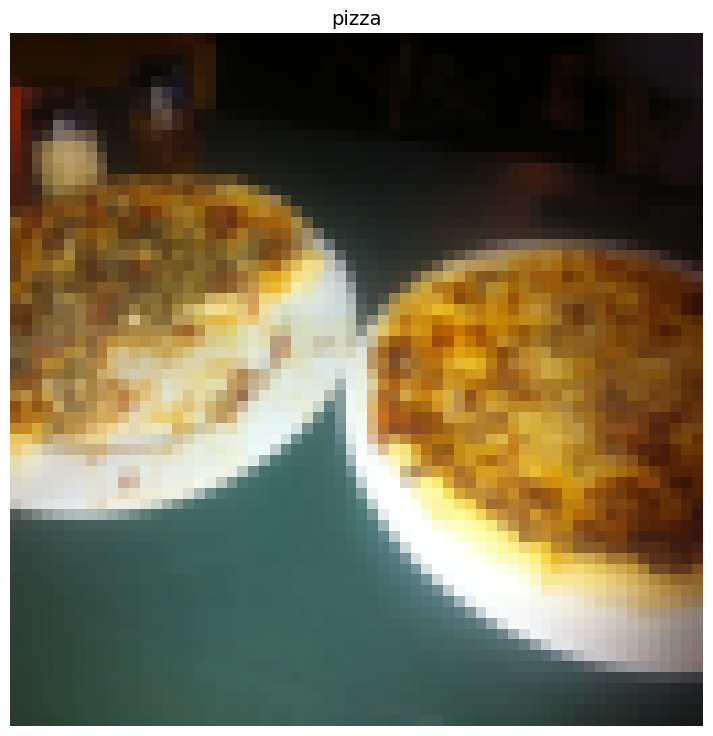

In [17]:
#rearrange the order of the dimension

image_permute = img.permute(1,2,0)

#print out different shapes( before and after premute)
print(f"The original image:{img.shape} [color_channel, height, width]")
print(f"Image permute shape:{image_permute.shape}[height, width,color_channels]")

#plot the image
plt.figure(figsize=(10,9))
plt.imshow(image_permute)
plt.axis("off")
plt.title(class_names[label], fontsize=14);



In [18]:
#turn train and test datasets into dataloader
from torch.utils.data import DataLoader

train_dataloader = DataLoader(dataset = train_data,
                              batch_size=1, #how many sample in a batch
                              num_workers=1, #how many subprocesses to use to use for data loading
                              shuffle=True)

test_dataloader = DataLoader(dataset=test_data,
                             batch_size=1,
                             num_workers=1,
                             shuffle=False) #usually dont need to shuffle test data

train_dataloader , test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7f12787de660>,
 <torch.utils.data.dataloader.DataLoader at 0x7f12786b79d0>)

In [19]:
img , label = next(iter(train_dataloader))

#batch size will now be 1, try changing batch size from parameter and see what happens
print(f"The shape of the image:{img.shape}[batch_size, color_channels, height, width]")
print(f"The shape of the label:{label.shape}")

The shape of the image:torch.Size([1, 3, 64, 64])[batch_size, color_channels, height, width]
The shape of the label:torch.Size([1])


Option 2: Loading Image Data with a Custom Dataset

In [20]:
import os
import pathlib
import torch

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple, Dict, List

In [21]:
import os #for dealing with directories
import pathlib  #for dealing with filepath (each of images has unique filepath)
import torch #torch for everything

from PIL import  Image #from Python Image Library import Image class
from torch.utils.data import  Dataset #to subclass from the module and create own custome dataset from Dataset
from torchvision import transforms #  to turn imges into tensors
from typing import Tuple, Dict, List # various types to add type hints to our code





Remember how our instances of torchvision.datasets.ImageFolder() allowed us to use the classes and class_to_idx attributes?

In [22]:
#instance of torchvision.datasets.Imagefolder()

train_data.classes , train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

Create a helper function to get class names

In [23]:
#setup path for target directory
target_directory = train_dir
print(f"Target directory:{target_directory}")

#Get the class names from the target directory
class_names_found = sorted([entry.name for entry in list(os.scandir(Image_path/ "train"))])
print(f"Class names found:{class_names_found}")


Target directory:Data/pizza_steak_sushi/train
Class names found:['pizza', 'steak', 'sushi']


In [24]:
# Make function to find classes in target directory
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
    """Finds the class folder names in a target directory.

    Assumes target directory is in standard image classification format.

    Args:
        directory (str): target directory to load classnames from.

    Returns:
        Tuple[List[str], Dict[str, int]]: (list_of_class_names, dict(class_name: idx...))

    Example:
        find_classes("food_images/train")
        >>> (["class_1", "class_2"], {"class_1": 0, ...})
    """
    # 1. Get the class names by scanning the target directory
    classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())

    # 2. Raise an error if class names not found
    if not classes:
        raise FileNotFoundError(f"Couldn't find any classes in {directory}.")

    # 3. Create a dictionary of index labels (computers prefer numerical rather than string labels)
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    return classes, class_to_idx

In [25]:
#make function to find classes in target directory

def find_classes(directory:str)-> Tuple[list[str], Dict[str,int]]:
    """
    Finds class folder names in the target directory

    Assume target directory in standard image classification format

    Args:
      directory(str): target directory to load classnames from

    Returns:
      Tuple[list[str], Dict[str, int]]: (list of class names, Dict(class names:idx....))

      Example: find_classes(food_image/"train")
      >>> (["class1", "class2", class3],{"class_1":0,...})

    """

    #1.get the class name by scannin target directory
    classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())

    #2. return error if class names not found
    if not classes:
      print(f"Couldn't find any classes in {directory}")


    #3. Return dictionary of classes and their indexes

    class_to_index = {cls_index: i for i,cls_index in enumerate(classes)}

    return classes, class_to_index








In [26]:
#lets test our find classes function

find_classes(train_dir)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

Create a custome dataset to replicate ImageFolder

In [27]:
#write a custom dataset class that inherits from torch.utils.data.Dataset

#1. Subclass torch.utils.data.Dataset
class ImageFolderCustom(torch.utils.data.Dataset):

  #initialize with target directory and transform (optional parameter)
  def __init__(self, target_dir:str, transform=None)-> None:

    #3. create class attributes
    #get all image paths
    self.paths = list(pathlib.Path(target_dir).glob("*/*.jpg")) #you would have to update this if you have .png or .jpeg

    #setup transforms
    self.transform = transform

    #create classes and class_to_idx attributes
    self.classes, self.class_to_idx = find_classes(target_dir)

  #4. make functions to load images
  def load_image(self, index:int) -> Image.Image:
    "opens and image via a path and returns it"
    Image_path = self.paths[index]
    return Image.open(Image_path)

  #5.overwrite the __len__() method (optional) but recommended for the subclass if torch.utils.data.Dataset
  def __len__(self)->int:
    "returns the total number of samples"
    return len(self.paths)

  #6. overwrite the __getitem__() method (required) for the subclass of torch.utils.data.Dataset
  def __getitem__(self, index:int)-> tuple[torch.tensor, int]:
    "returns one sample of data. data and label (x,y)"
    img = self.load_image(index)
    class_name = self.paths[index].parent.name  #expects path in data_folder/class_name/image.jpg
    class_index = self.class_to_idx[class_name]

    #transform if necessary
    if self.transform:
      return self.transform(img), class_index #return data, label (x,y)
    else:
      return img, class_index #return data, label (x,y)






In [28]:
#lets create some transforms to prepare our image

#augment train data

train_transforms = transforms.Compose([transforms.Resize((64,64)),
                                       transforms.RandomHorizontalFlip(p=0.5),
                                       transforms.ToTensor()])

#dont augment test data only reshape
test_transforms = transforms.Compose([transforms.Resize((64,64)),
                                      transforms.ToTensor()])



Let's turn our training images (contained in train_dir) and our testing images (contained in test_dir) into Dataset's using our own ImageFolderCustom class.

In [29]:
train_data_custom = ImageFolderCustom(target_dir=train_dir,
                                      transform=train_transforms)

test_data_custom = ImageFolderCustom(target_dir=test_dir,
                                     transform = test_transforms)

train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x7f12787dfb60>,
 <__main__.ImageFolderCustom at 0x7f12786cd090>)

Let's try calling len() on our new Dataset's and find the classes and class_to_idx attributes.

In [30]:
len(train_data_custom) , len(test_data_custom)

(225, 75)

In [31]:
train_data_custom.classes

['pizza', 'steak', 'sushi']

In [32]:
train_data_custom.class_to_idx

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [33]:
#check for the equality for our custom dataset and torch.utils.dara.Datasets

print((len(train_data_custom)==len(train_data)) & (len(test_data_custom)==len(test_data)))
print(len(train_data_custom.classes)==len(train_data.classes))
print(len(train_data_custom.class_to_idx)==len(train_data.class_to_idx))

True
True
True


In [34]:
# 1. Take in a Dataset as well as a list of class names
def display_random_images(dataset: torch.utils.data.dataset.Dataset,
                          classes: List[str] = None,
                          n: int = 10,
                          display_shape: bool = True,
                          seed: int = None):

    # 2. Adjust display if n too high
    if n > 10:
        n = 10
        display_shape = False
        print(f"For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.")

    # 3. Set random seed
    if seed:
        random.seed(seed)

    # 4. Get random sample indexes
    random_samples_idx = random.sample(range(len(dataset)), k=n)

    # 5. Setup plot
    plt.figure(figsize=(16, 8))

    # 6. Loop through samples and display random samples
    for i, targ_sample in enumerate(random_samples_idx):
        targ_image, targ_label = dataset[targ_sample][0], dataset[targ_sample][1]

        # 7. Adjust image tensor shape for plotting: [color_channels, height, width] -> [color_channels, height, width]
        targ_image_adjust = targ_image.permute(1, 2, 0)

        # Plot adjusted samples
        plt.subplot(1, n, i+1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")
        if classes:
            title = f"class: {classes[targ_label]}"
            if display_shape:
                title = title + f"\nshape: {targ_image_adjust.shape}"
        plt.title(title)

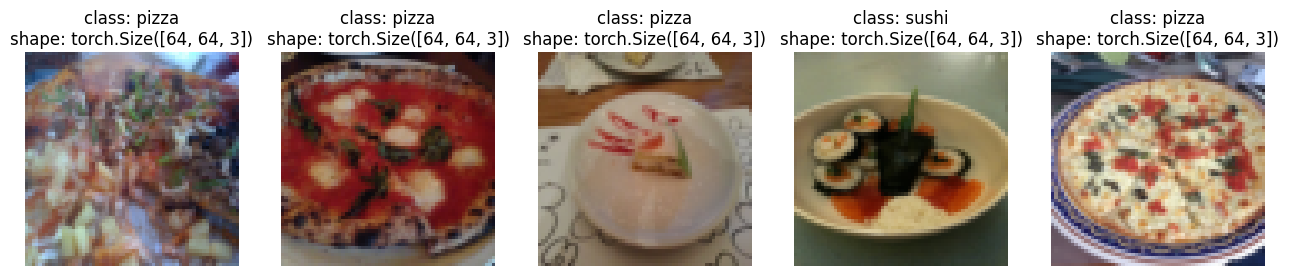

In [35]:
#Display random images form the ImageFolder created Datset

display_random_images(dataset=train_data,
                      n=5,
                      classes = class_names,
                      seed=None)


For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.


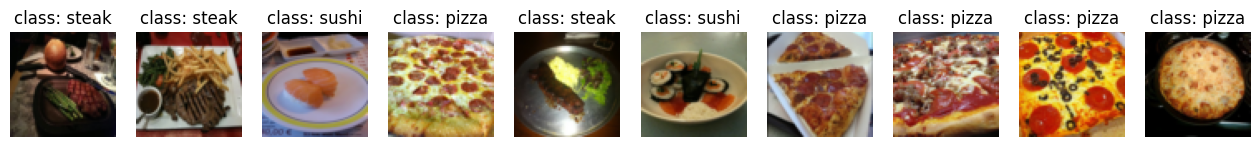

In [36]:
#Now display random images from the ImageFolderCustom we created

display_random_images(dataset=train_data_custom,
                      classes = class_names,
                      n=12,
                      seed=None)

In [37]:
#turn train and test custom datasets into Dataloaders
from torch.utils.data import DataLoader

train_dataloader_custom = DataLoader(dataset=train_data_custom,
                                     batch_size=1, #how many samples per batch
                                     num_workers=0, #number of subprocesses used for dataloading
                                     shuffle=True)  #shuffle the samples

test_dataloader_custom = DataLoader(dataset=test_data_custom,
                                     batch_size=1,
                                     num_workers=0,
                                     shuffle=False) #dont usually need to shuffle testing data


train_dataloader_custom , test_dataloader_custom


(<torch.utils.data.dataloader.DataLoader at 0x7f12782bbd90>,
 <torch.utils.data.dataloader.DataLoader at 0x7f1278740c30>)

In [38]:
#get the image and label from custom dataloader

img_custom , label_custom = next(iter(train_dataloader_custom))

#batch size now will be one , try changing batch size parameter above and see what happens
print(f"Image shape:{img_custom.shape}")
print(f"label shape:{label_custom.shape}")


Image shape:torch.Size([1, 3, 64, 64])
label shape:torch.Size([1])


In [39]:
from torchvision import transforms

train_transform = transforms.Compose([
                  transforms.Resize((224,224)),
                  transforms.TrivialAugmentWide(num_magnitude_bins=31),
                  transforms.ToTensor()]
                  )

test_transform = transforms.Compose([
                  transforms.Resize((24,24)),
                  transforms.ToTensor()
])

Beautiful, now we've got a training transform (with data augmentation) and test transform (without data augmentation).

Let's test our data augmentation out!

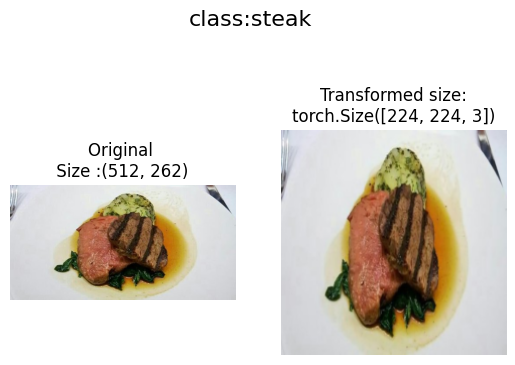

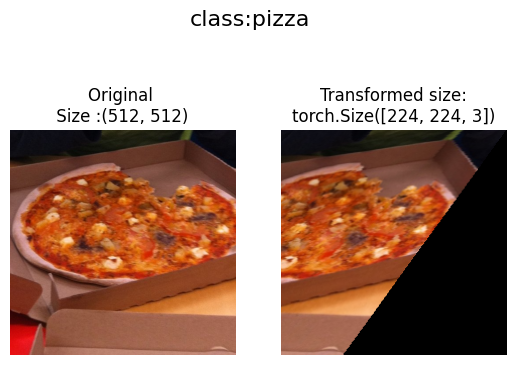

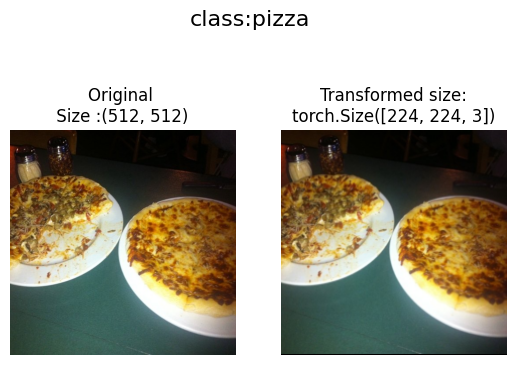

In [40]:
#get all the image paths

image_paths = list(Image_path.glob("*/*/*.jpg"))

#plot random images
plot_transformed_images(image_paths= image_paths,
                        transform = train_transform,
                        n=3,
                        seed=None)



Model 0: TinyVGG without data augmentation

In [41]:
#lets create a simple transformation without augemntation

simple_trasform = transforms.Compose([
    transforms.Resize((64,64)),
    transforms.ToTensor()
])

In [42]:
#1. load and transform data

train_data_simple = datasets.ImageFolder(root=train_dir, transform= simple_trasform)
test_data_simple = datasets.ImageFolder(root=test_dir , transform=simple_trasform)

#2.trun data into dataloaders
import os
from torch.utils.data import DataLoader

#3. setup batch size and number of workers

BATCH_SIZE = 3
NUM_WORKERS = os.cpu_count()
print(f"Creating the batch size of :{BATCH_SIZE} and number of workers :{NUM_WORKERS}")

#4. create dataloaders

train_dataloader_simple = DataLoader(train_data_simple,
                                     batch_size=BATCH_SIZE,
                                     shuffle=True,
                                     num_workers = NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    shuffle=False,
                                    num_workers=NUM_WORKERS)

train_dataloader_simple , test_dataloader_simple

Creating the batch size of :3 and number of workers :2


(<torch.utils.data.dataloader.DataLoader at 0x7f1278741ba0>,
 <torch.utils.data.dataloader.DataLoader at 0x7f12780e5130>)

In [43]:
#lets create a TinyVGG model class

class TinyVGG(nn.Module):

  """ Copying TinyVGG Model Architecture from:
      https://poloclub.github.io/cnn-explainer/
    """
  def __init__(self, input_shape:int, hidden_units:int, output_shape:int) ->None:
    super().__init__()
    self.Conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,
                  kernel_size=3,  #how big is the square that goes over the image
                  stride=1, #default
                  padding=1 # options = "valid" (no padding) or "same" (output has same shape as input) or int for specific number

                  ),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                      stride=2)  #default value as same as kernel_size
    )
    self.Conv_block_2 = nn.Sequential(
                        nn.Conv2d(hidden_units,hidden_units,kernel_size=3, padding=1),
                        nn.ReLU(),
                        nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
                        nn.ReLU(),
                        nn.MaxPool2d(2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*16*16,
                  out_features=output_shape)
    )

  def forward(self,x: torch.Tensor)-> torch.Tensor:
    x = self.Conv_block_1(x)
    # print(x.shape) # Removed for cleaner output
    x = self.Conv_block_2(x)
    # print(x.shape) # Removed for cleaner output
    x = self.classifier(x)
    # print(x.shape) # Removed for cleaner output
    return x
    #return self.classifier(self.Con_block_2(self.Conv_block_1(x))) # -> leverage the benefits of operator fusion

torch.manual_seed(42)

model_0 = TinyVGG(input_shape=3, #the number of input color i.e 3 (RBG) color values here)
                  hidden_units=10,
                  output_shape= len(train_data.classes)).to(device)


model_0


TinyVGG(
  (Conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (Conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [44]:
#get a batch of image and labels from the dataset

image_batch , label_batch = next(iter(train_dataloader_simple))

#get a single image from batch and unsqueeze so its shape fits the model

image_single , label_single = image_batch[0].unsqueeze(dim=0) , label_batch[0]
print(f"Single image shape:{image_single.shape}")

#3. perform the forward pass on single image
model_0.eval()
with torch.inference_mode():

  y_logits = model_0(image_single.to(device))

  #pred probabiliy
  pred_prob = torch.softmax(y_logits, dim=1)

  #pred label
  pred_label = torch.argmax(pred_prob, dim=1)


print(f"The output logits:{y_logits}")
print(f"The prediction probability;{pred_prob}")
print(f"The prediction label :{pred_label}")
print(f"The acutual label:{label_single}")




Single image shape:torch.Size([1, 3, 64, 64])
The output logits:tensor([[0.0578, 0.0634, 0.0351]], device='cuda:0')
The prediction probability;tensor([[0.3352, 0.3371, 0.3277]], device='cuda:0')
The prediction label :tensor([1], device='cuda:0')
The acutual label:2


In [45]:
#try installing torchinfo if not install it

try:
  import torchinfo
except:
  !pip install torchinfo
  import torchinfo

from torchinfo import summary
summary(model_0, input_size=[1,3,64,64]) #do a test pass through of an example input size


Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 10, 64, 64]           280
│    └─ReLU: 2-2                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 10, 64, 64]           910
│    └─ReLU: 2-4                         [1, 10, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 10, 32, 32]           --
├─Sequential: 1-2                        [1, 10, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 10, 32, 32]           910
│    └─ReLU: 2-7                         [1, 10, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 10, 32, 32]           910
│    └─ReLU: 2-9                         [1, 10, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 10, 16, 16]           --
├─Sequentia

In [46]:
#lets define the train_step and test step

def train_step(model:torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn = torch.nn.Module,
               optimizer = torch.optim.Optimizer
               ):
  #put the model in training mode
  model.train()

  #set the train loss and accuracy to intial zero
  train_loss , train_accuracy = 0,0

  #loop through the data loader through batches
  for batch, (x,y) in enumerate(dataloader):

    #put the data and label in the cuda device
    x , y  =x.to(device) , y.to(device)

    #forward function

    y_pred = model(x)

    #calculate loss function
    loss = loss_fn(y_pred , y)
    train_loss += loss.item() #changing tensor value to python integer

    #optimizer zero grad
    optimizer.zero_grad()

    #loss backward
    loss.backward()

    #optimizer step
    optimizer.step()

    #calculate the accumulate accuracy metrics across all batches
    y_pred_classes = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_accuracy += (y_pred_classes == y).sum().item() / len(y_pred)

  #calculate the average model train loss and accuracy
  train_loss = train_loss / len(dataloader)
  train_accuracy = train_accuracy / len(dataloader)

  return train_loss , train_accuracy




In [47]:
#lets define the test step
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn = torch.nn.Module):

  #put the model in eval mode
  model.eval()

  #set the loss and accuracy
  test_loss , test_accuracy = 0,0

  #loop through the dataloader and run inference
  for batch , (x,y) in enumerate(dataloader):

    #put the data in respective device
    x , y = x.to(device) , y.to(device)

    #1. forward pass
    y_pred_logits = model(x)

    #calculate  and accumulate the loss
    loss = loss_fn(y_pred_logits, y)
    test_loss += loss.item() # Accumulate item() for scalar sum

    #calculate and accumulate the accuracy
    test_pred_labels = torch.argmax(y_pred_logits , dim=1)
    test_accuracy += (test_pred_labels ==y).sum().item() / len(test_pred_labels)


  #total test loss and accuracy over the dataset
  test_loss = test_loss / len(dataloader) # Corrected: Divide accumulated loss by number of batches
  test_accuracy = test_accuracy / len(dataloader)

  return test_loss , test_accuracy

In [48]:
#lets create train function to combine train step and test step

from tqdm.auto import tqdm

#take in various parameters required for the training and test step

def train(model: torch.nn.Module, train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer:torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int=5):

  #lets create  empty results dictionary

  results = {"train loss":[],
             "train accuracy":[],
             "test loss":[],
             "test accuracy":[]}

  #loop through trainig and testing epoch
  for epoch in tqdm(range(epochs)):

    train_loss , train_accuracy = train_step(model= model,
                                             dataloader=train_dataloader,
                                             loss_fn= loss_fn,
                                             optimizer=optimizer)

    test_loss , test_accuracy = test_step(model=model,
                                          dataloader=test_dataloader,
                                          loss_fn = loss_fn)

    #print out whats happpening
    print(f"epoch:{epoch}|"
    f"train loss:{train_loss}|"
    f"train accuracy:{train_accuracy}|"
    f"test loss:{test_loss}"
    f"test accuracy:{test_accuracy}"

    )

    #add these results in the didctioarny we created making sure all data moved to cpu and all tensors converted to float
    results["train loss"].append(train_loss.item() if isinstance(train_loss , torch.Tensor) else train_loss)
    results["train accuracy"].append(train_accuracy.item() if isinstance(train_accuracy , torch.Tensor) else train_accuracy)
    results["test loss"].append( test_loss.item() if isinstance(test_loss , torch.Tensor) else test_loss)
    results["test accuracy"].append(test_accuracy.item() if isinstance(test_accuracy, torch.Tensor)else test_accuracy)

  #return the filled results at the end of the epoch
  return results



 Train and Evaluate Model 0

In [49]:
#set random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

#set number of epochs
num_epochs = 5

#create  our model instance
model_0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)

#set the loss function and optinizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters() , lr=0.001)

#start the timer to record the train time of model
from timeit import default_timer as timer
start_train_time = timer()

model_0_results = train(model=model_0,
                        train_dataloader = train_dataloader_simple, #the actual sanple batched dataset we created before
                        test_dataloader = test_dataloader_simple,
                        loss_fn = loss_fn,
                        optimizer= optimizer,
                        epochs = num_epochs)

#end the timer and print how long it took
end_train_time = timer()
print(f"Total trainig time:{ end_train_time - start_train_time:.3f} seconds")





  0%|          | 0/5 [00:00<?, ?it/s]

epoch:0|train loss:1.1142987696329754|train accuracy:0.3199999999999999|test loss:1.097933144569397test accuracy:0.33333333333333337
epoch:1|train loss:1.101495795249939|train accuracy:0.29333333333333317|test loss:1.0996295833587646test accuracy:0.2533333333333333
epoch:2|train loss:1.099371887842814|train accuracy:0.3111111111111111|test loss:1.099851360321045test accuracy:0.33333333333333337
epoch:3|train loss:1.0988109302520752|train accuracy:0.3333333333333334|test loss:1.1007301092147828test accuracy:0.2533333333333333
epoch:4|train loss:1.0996099106470745|train accuracy:0.32888888888888895|test loss:1.1000472831726074test accuracy:0.3733333333333334
Total trainig time:10.876 seconds


Plot the loss curves of Model 0

In [50]:
#check the model result keys
model_0_results.keys()

dict_keys(['train loss', 'train accuracy', 'test loss', 'test accuracy'])

In [51]:

#lets plot the loss curves

def plot_loss_curves(results: Dict[str, list[float]]):
  """plots the training curve of the model
  Args:
    results(dict) : a dictionary containing of list values e.g
      {"train loss:[.....],
      "train accuracy:[.....],
      "test loss:[.....],
      "test accuracy:[.....]
      }
      """

  #get the loss values of training and test loss
  loss = results["train loss"]
  test_loss = results["test loss"]

  #get the accuracy values of train and test
  accuracy = results["train accuracy"]
  test_accuracy = results["test accuracy"]

  #figure out how many epochs are there
  epochs  = range(len(results["test loss"]))

  #setup a plot
  plt.figure(figsize=(15,7))

  #plot loss
  plt.subplot(1,2,1)
  plt.plot(epochs, loss, label='train_loss')
  plt.plot(epochs, test_loss , label="test_loss")
  plt.title("Loss")
  plt.xlabel("Epochs")
  plt.ylabel("loss values")
  plt.legend()

  #plot accuracy
  plt.subplot(1,2,2)
  plt.plot(epochs, accuracy, label="train accuracy")
  plt.plot(epochs, test_accuracy, label="test accuracy")
  plt.title("Accuracy")
  plt.xlabel("Epochs")
  plt.ylabel("Accuracy %")
  plt.legend()

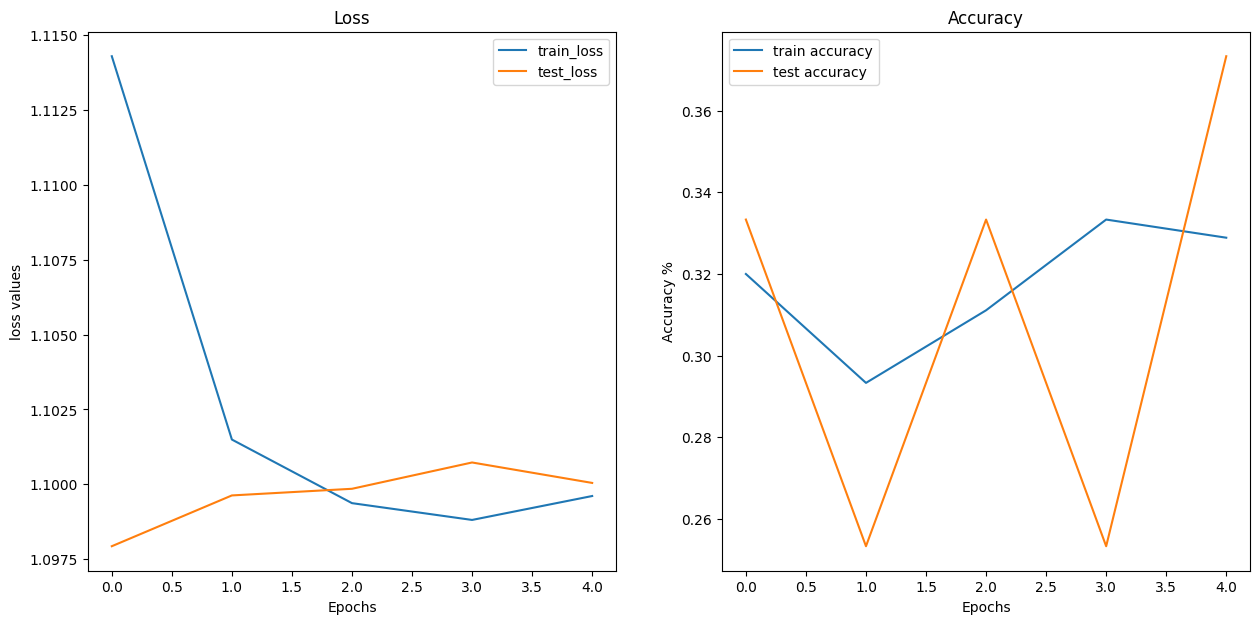

In [52]:
plot_loss_curves(model_0_results);

Model 1: TinyVGG with Data Augmentation

In [53]:
#create transform with data augmentation i.e training data with trivialaugment

train_transform_trivialAugment = transforms.Compose(
                                [transforms.Resize((64,64)),
                                transforms.TrivialAugmentWide(num_magnitude_bins=31),
                                transforms.ToTensor()])


test_transform = transforms.Compose(
                                [transforms.Resize((64,64)),
                                transforms.ToTensor()])



Create train and test Dataset's and DataLoader's

In [54]:
#lets turn the image folders into datasets

train_data_trivialAugment = datasets.ImageFolder(root=train_dir, transform = train_transform_trivialAugment)
test_data_simple = datasets.ImageFolder(root=test_dir, transform = test_transform)

train_data_trivialAugment , test_data_simple

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: Data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: Data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ))

In [55]:
#lets turn the datasets into dataloaders

import os

BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

#now lets turn train and test datasets into dataloaders
torch.manual_seed(42)
train_dataloader_augmented = DataLoader(train_data_trivialAugment,
                                        batch_size=BATCH_SIZE,
                                        shuffle = True,
                                        num_workers = NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple,
                                    batch_size= BATCH_SIZE,
                                    shuffle = True,
                                    num_workers = NUM_WORKERS)

(train_dataloader_augmented) , (test_dataloader_simple)

(<torch.utils.data.dataloader.DataLoader at 0x7f1278a27130>,
 <torch.utils.data.dataloader.DataLoader at 0x7f1278a26360>)

Construct and train Model 1

In [56]:
#lets create a new model and send it yo target device

torch.manual_seed(42)

model_1 = TinyVGG(input_shape=3,
                  hidden_units = 10,
                  output_shape = len(train_data_trivialAugment.classes)).to(device)

model_1

TinyVGG(
  (Conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (Conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [57]:
#Lets train the model with predefined train and test steps with time stamp

torch.manual_seed(42)
torch.cuda.manual_seed(42)

#set the number of epochs
NUM_EPOCHS = 5 # Increased from 5 to 20 for better learning

#define loss function and opimizer

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.001)

#start the timer
train_start_time = timer()

#train_model

model_1_results = train(model=model_1,
                        train_dataloader = train_dataloader_augmented,
                        test_dataloader = test_dataloader_simple,
                        loss_fn = loss_fn,
                        optimizer = optimizer,
                        epochs = NUM_EPOCHS )

#stop the timer
train_end_time = timer()

#print the timer taken to train model
print(f"The total time taken by model to train:{train_end_time - train_start_time}")

  0%|          | 0/5 [00:00<?, ?it/s]

epoch:0|train loss:1.1075639575719833|train accuracy:0.25|test loss:1.1044209400812786test accuracy:0.2604166666666667
epoch:1|train loss:1.0786502808332443|train accuracy:0.42578125|test loss:1.1138382355372112test accuracy:0.33996212121212127
epoch:2|train loss:1.136318102478981|train accuracy:0.3046875|test loss:1.1083884636561077test accuracy:0.35984848484848486
epoch:3|train loss:1.088773936033249|train accuracy:0.42578125|test loss:1.0919427474339802test accuracy:0.35984848484848486
epoch:4|train loss:1.1089363545179367|train accuracy:0.3046875|test loss:1.094852050145467test accuracy:0.33996212121212127
The total time taken by model to train:9.100003991999984


Plot the loss curves of Model 1

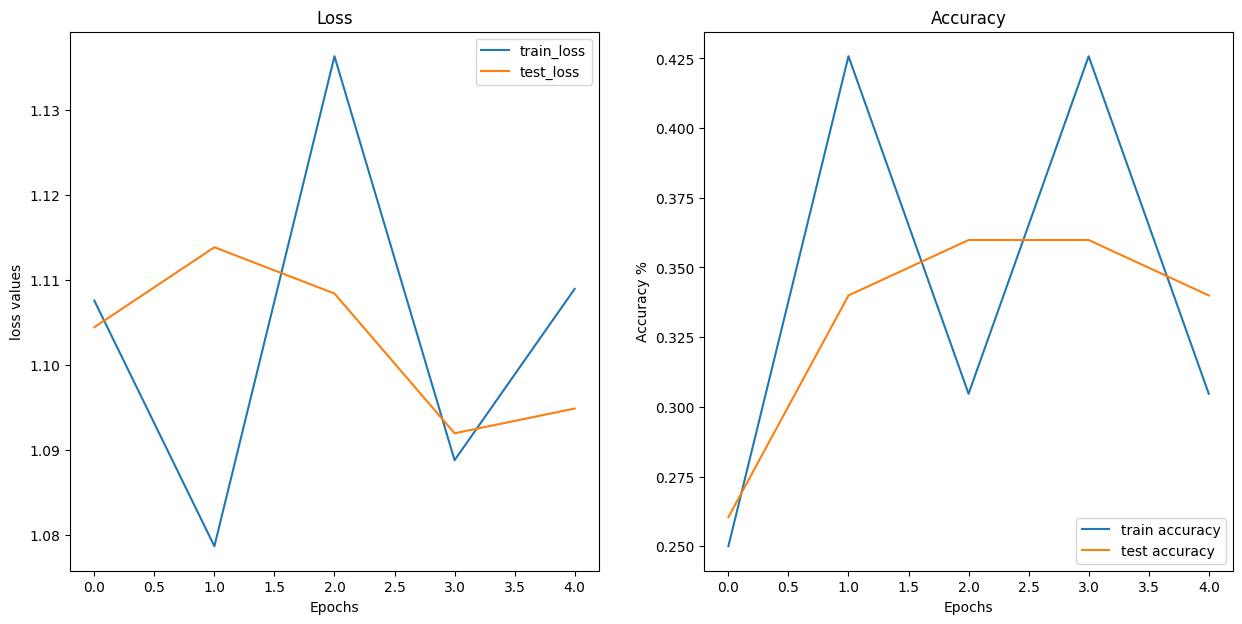

In [58]:
plot_loss_curves(model_1_results);

Compare model results

In [59]:
import pandas as pd

model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df

,train loss,train accuracy,test loss,test accuracy
0,1.114299,0.320000,1.097933,0.333333
1,1.101496,0.293333,1.099630,0.253333
2,1.099372,0.311111,1.099851,0.333333
3,1.098811,0.333333,1.100730,0.253333
4,1.099610,0.328889,1.100047,0.373333


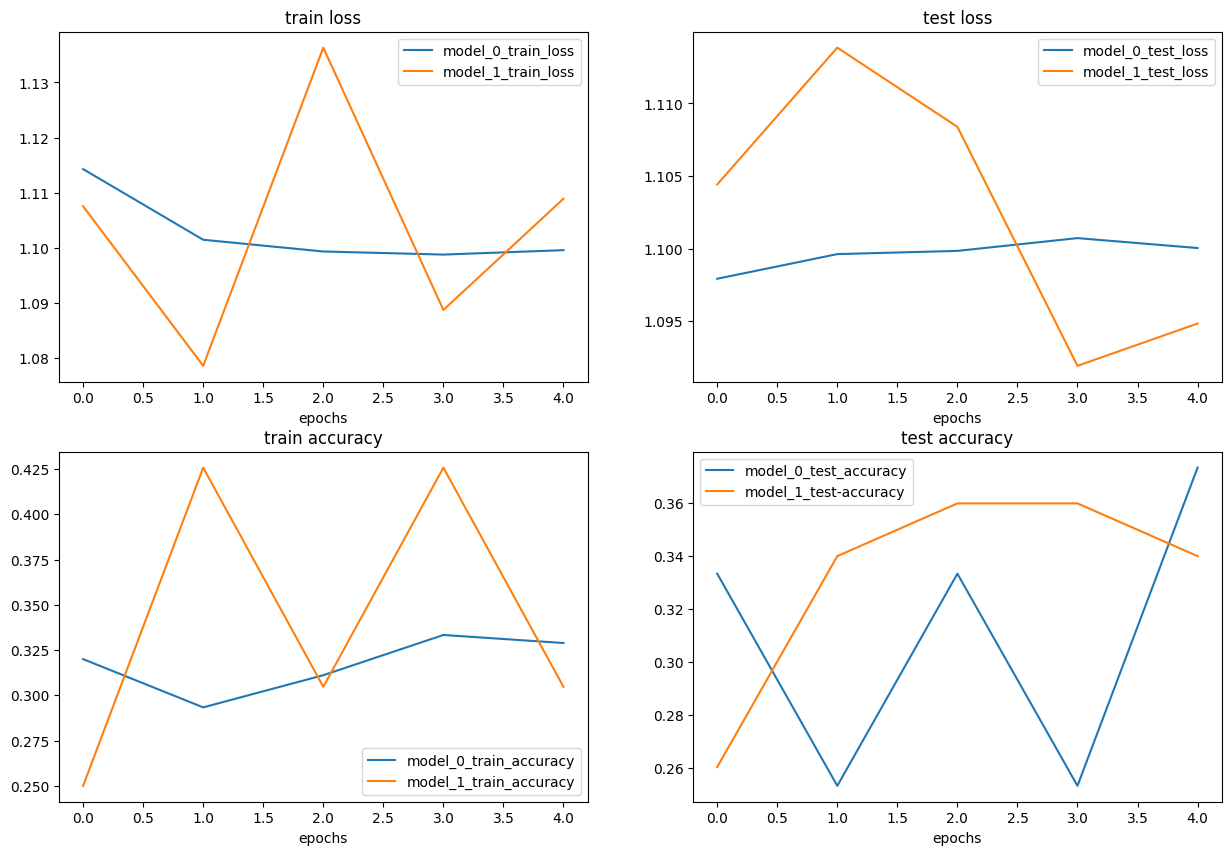

In [60]:
#setup a plot

plt.figure(figsize=(15,10))

#get number of epochs

epochs =  range(len(model_0_df))

#plot train loss

plt.subplot(2,2,1)
plt.plot(epochs, model_0_results["train loss"], label = "model_0_train_loss")
plt.plot(epochs, model_1_results["train loss"], label="model_1_train_loss")
plt.title("train loss")
plt.xlabel("epochs")
plt.legend()

#plot test loss
plt.subplot(2,2,2)
plt.plot(epochs, model_0_results["test loss"], label="model_0_test_loss")
plt.plot(epochs, model_1_results["test loss"], label="model_1_test_loss")
plt.title("test loss")
plt.xlabel("epochs")
plt.legend()

#plot train accuracy
plt.subplot(2,2,3)
plt.plot(epochs, model_0_results["train accuracy"], label="model_0_train_accuracy")
plt.plot(epochs, model_1_results["train accuracy"], label="model_1_train_accuracy")
plt.title("train accuracy")
plt.xlabel("epochs")
plt.legend()

#plot test accuracy
plt.subplot(2,2,4)
plt.plot(epochs, model_0_results["test accuracy"], label="model_0_test_accuracy")
plt.plot(epochs, model_1_results["test accuracy"],label="model_1_test-accuracy")
plt.title("test accuracy")
plt.xlabel("epochs")
plt.legend();

In [61]:
#Its tiome to predict the imahe

#download custom image
import requests
from pathlib import Path

# Define the path to the prediction folder
pred_folder = Path('/content/pred_folder/')

# Create the prediction folder if it doesn't exist
pred_folder.mkdir(parents=True, exist_ok=True)

#setup the custom image path
custom_image_path = pred_folder/"Cooked-Sushi-Roll.jpg"

#download the image if it doesnt exists already
if not custom_image_path.is_file():
  with open(custom_image_path, "wb") as f:
    # When downloading from GitHub, need to use the "raw" file link
    requests = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
    print(f"Downloading the {custom_image_path}.......")
    f.write(requests.content)
else:
  print(f"{custom_image_path} already exists. Skipping download ")

 Loading in a custom image with PyTorch

In [62]:
import torchvision

#load in custom image and convert the tensor values into (float32)
custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)

#divide the pixel value by 255 to get the values between 0 and 1
custom_image = custom_image / 255


#print out image data
print(f"The custom image tensor:{custom_image}")
print(f"The custom image shape:{custom_image.shape}")
print(f"The custom image dtype:{custom_image.dtype}")

The custom image tensor:tensor([[[0.6039, 0.6784, 0.7098,  ..., 0.0824, 0.0706, 0.0549],
         [0.5725, 0.6471, 0.7098,  ..., 0.0824, 0.0706, 0.0588],
         [0.4863, 0.5725, 0.6745,  ..., 0.0706, 0.0667, 0.0588],
         ...,
         [0.2824, 0.2314, 0.1765,  ..., 0.5961, 0.5882, 0.5804],
         [0.2510, 0.2157, 0.1608,  ..., 0.5882, 0.5765, 0.5647],
         [0.2510, 0.2353, 0.1804,  ..., 0.5843, 0.5725, 0.5608]],

        [[0.6706, 0.7451, 0.7569,  ..., 0.0863, 0.0745, 0.0588],
         [0.6392, 0.7137, 0.7569,  ..., 0.0863, 0.0745, 0.0627],
         [0.5529, 0.6392, 0.7216,  ..., 0.0745, 0.0706, 0.0627],
         ...,
         [0.2157, 0.1647, 0.1098,  ..., 0.4196, 0.4078, 0.4039],
         [0.1843, 0.1490, 0.0941,  ..., 0.4235, 0.4078, 0.4000],
         [0.1843, 0.1686, 0.1137,  ..., 0.4196, 0.4078, 0.3961]],

        [[0.4667, 0.5412, 0.5765,  ..., 0.0667, 0.0549, 0.0392],
         [0.4353, 0.5098, 0.5686,  ..., 0.0667, 0.0549, 0.0431],
         [0.3412, 0.4353, 0.5333, 

Predicting on custom images with a trained PyTorch mode

Before we answer that question, let's plot the image with matplotlib to make sure it looks okay, remember we'll have to permute the dimensions from CHW to HWC to suit matplotlib's requirements.

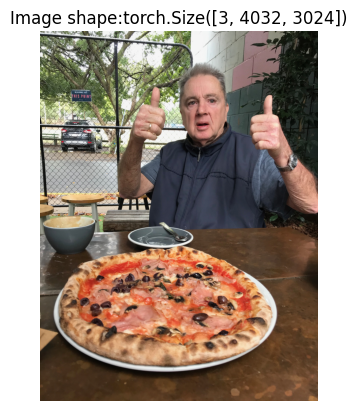

In [63]:
#plot custom imahe

plt.imshow(custom_image.permute(1,2,0))
plt.title(f"Image shape:{custom_image.shape}")
plt.axis(False);


In [64]:
#create the transform pipeline to resize the image

custom_image_transform = transforms.Compose(
                        [transforms.Resize((64,64))])

#transform target image
custom_image_transformed = custom_image_transform(custom_image)

#print out original shape and new shape

print(f"The Original shape:{custom_image.shape}")
print(f"The new shape of custom image:{custom_image_transformed.shape}")




The Original shape:torch.Size([3, 4032, 3024])
The new shape of custom image:torch.Size([3, 64, 64])


In [65]:
#lets run the inference on new transformed image

model_1.eval()
with torch.inference_mode():

  #lets add extra dimension necessary to make prediction
  custom_image_transformed_with_batchsize = custom_image_transformed.unsqueeze(dim=0)

  #print out the different shapes
  print(f"The shape of image before:{custom_image_transformed.shape}")
  print(f"The shape of image after:{custom_image_transformed_with_batchsize.shape}")

  #now lets run the inference mode
  custom_image_pred = model_1(custom_image_transformed_with_batchsize.to(device)) #dont forget to put the image in same device as model


The shape of image before:torch.Size([3, 64, 64])
The shape of image after:torch.Size([1, 3, 64, 64])


Note: What we've just gone through are three of the classical and most common deep learning and PyTorch issues:

Wrong datatypes - our model expects torch.float32 where our original custom image was uint8.
Wrong device - our model was on the target device (in our case, the GPU) whereas our target data hadn't been moved to the target device yet.
Wrong shapes - our model expected an input image of shape [N, C, H, W] or [batch_size, color_channels, height, width] whereas our custom image tensor was of shape [color_channels, height, width].
Keep in mind, these errors aren't just for predicting on custom images.

They will be present with almost every kind of data type (text, audio, structured data) and problem you work with.

In [66]:
custom_image_pred

tensor([[ 0.0994, -0.0739, -0.0341]], device='cuda:0')

Alright, these are still in logit form (the raw outputs of a model are called logits).

Let's convert them from logits -> prediction probabilities -> prediction labels.

In [67]:
#print out model logits
print(f"The prediction logits:{custom_image_pred}")

#convert logits into prediction probability
custom_image_pred_prob = torch.softmax(custom_image_pred , dim=1)
print(f"The prediction probability:{custom_image_pred_prob}")

#now convert the image pred probability into preditiction labels

custom_image_pred_label = torch.argmax(custom_image_pred_prob, dim=1)
print(f"The prediction label:{custom_image_pred_label}")

The prediction logits:tensor([[ 0.0994, -0.0739, -0.0341]], device='cuda:0')
The prediction probability:tensor([[0.3682, 0.3096, 0.3222]], device='cuda:0')
The prediction label:tensor([0], device='cuda:0')


In [68]:
#find the prediction label

image_prediction_class = class_names[custom_image_pred_label.cpu()]  #put the label to cpu else error occurs
image_prediction_class

'pizza'

In [69]:
#the value of predicted probabilities are quite similar

custom_image_pred_prob

tensor([[0.3682, 0.3096, 0.3222]], device='cuda:0')

In [70]:
def pred_and_plot_image(model: torch.nn.Module,
                        image_path: str,
                        class_names: List[str] = None,
                        transform=None,
                        device: torch.device = device):
    """Makes a prediction on a target image and plots the image with its prediction."""

    # 1. Load in image and convert the tensor values to float32
    target_image = torchvision.io.read_image(str(image_path)).type(torch.float32)

    # 2. Divide the image pixel values by 255 to get them between [0, 1]
    target_image = target_image / 255.

    # 3. Transform if necessary
    if transform:
        target_image = transform(target_image)

    # 4. Make sure the model is on the target device
    model.to(device)

    # 5. Turn on model evaluation mode and inference mode
    model.eval()
    with torch.inference_mode():
        # Add an extra dimension to the image
        target_image = target_image.unsqueeze(dim=0)

        # Make a prediction on image with an extra dimension and send it to the target device
        target_image_pred = model(target_image.to(device))

    # 6. Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # 7. Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # 8. Plot the image alongside the prediction and prediction probability
    plt.imshow(target_image.squeeze().permute(1, 2, 0)) # make sure it's the right size for matplotlib
    if class_names:
        title = f"Pred: {class_names[target_image_pred_label.cpu()]} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    else:
        title = f"Pred: {target_image_pred_label} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    plt.title(title)
    plt.axis(False);

In [71]:
def pred_and_plot_image(model:torch.nn.Module,
                        image_path: str,
                        class_names = list[str],
                        transform=None,
                        device : torch.device = device):
  """ This functionb automates the prediction of new image and plots the image as well"""

  #1. Take the target image and turn them into tensor of float32
  target_image = torchvision.io.read_image(str(image_path)).type(torch.float32)


  #Divide the image pixel value to get between [0] and [1]
  target_image = target_image / 255

  #3. transform the image if necessary
  if transform:
    target_image = transform(target_image)

  #4. make sure model is on the right device
  model.to(device)

  #5. turn model evaluation mode and inference mode
  model.eval()
  with  torch.inference_mode():
    #6. Run the inference after creating the batch size and make sure the image is also on same device as model
    target_image_pred = model(target_image.unsqueeze(dim=0).to(device))

    #7. Apply softmax activation function to predict the class labels from raw logits
    target_image_pred_probs = torch.softmax(target_image_pred , dim=1)

    #8. Apply the arg max function to pick up the class label from pred probs
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    #9. plot the image alongside prediction and prediction probability
    plt.imshow(target_image.permute(1,2,0)) #right format for the matplotlib [H,W,C]
    if class_names:
      title = f"pred:{class_names[target_image_pred_label.cpu()]} | Prob:{target_image_pred_probs.max().cpu():.3f}"
    else:
      title = f"Pred:{target_image_pred_label} | Prob:{target_image_pred_probs.max():3f}"
    plt.title(title)
    plt.axis(False);



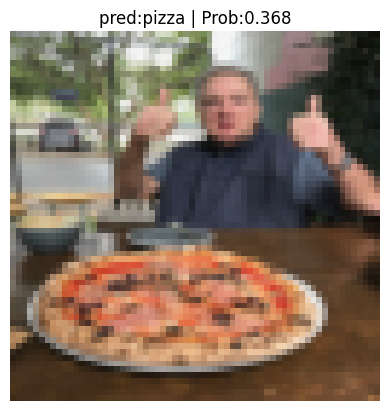

In [72]:
#pred on our custom image
pred_and_plot_image(model=model_1,
                    image_path=custom_image_path,
                    class_names=class_names,
                    transform=custom_image_transform,
                    device=device);